In [ ]:
import os
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import numpy as np

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

In [ ]:
#Feature
def generate_batch(batch_size, S, n):
    input1 = torch.rand(batch_size, n)
    input2 = torch.rand(batch_size, n)
    dataset = input1 * torch.gt(input2, S).float()
    return dataset

In [ ]:
# Neural Network Model
class NeuralNetwork(nn.Module):
    def __init__(self, n, m, activation):
        super(NeuralNetwork, self).__init__()
        self.n = n
        self.m = m
        self.weight = nn.init.xavier_normal_(torch.rand(m, n))
        self.bias = torch.zeros(n)
        self.activation = activation
        self.weight = nn.Parameter(self.weight)
        self.bias = nn.Parameter(self.bias)


    def forward(self, x):
        h = torch.matmul(x, self.weight.t())
        x_prime = self.activation(torch.matmul(h, self.weight) + self.bias)
        return x_prime
    

In [ ]:
n = 5 # number of input features
m = 2 # number of hidden units
importance = torch.arange(0, n).float()  # importance of each feature
importance = torch.pow(0.7, importance)  # apply a power transformation to the importance values
def loss_fn (x, x_prime, importance):
    return torch.sum(importance * (x - x_prime) ** 2, dim=1).mean()
# m < n to ensure that the model is underparameterized
model = NeuralNetwork(n, m, nn.ReLU())
dataset = generate_batch(3, 0, n)

In [45]:
# Training loop model function
def train_model(n, batch_size, S, model, importance, epochs=7000, learning_rate=1e-3):
    optimizer = torch.optim.Adam(model.parameters(), lr = learning_rate)
    for epoch in range(epochs):
        dataset = generate_batch(batch_size, S, n)
        optimizer.zero_grad()
        x_prime = model(dataset)
        loss = loss_fn(dataset, x_prime, importance)
        loss.backward()
        optimizer.step()
        if epoch == epochs - 1:
            weight = model.weight.detach().clone().numpy()
    print(S, loss.item())
    return weight

0.9 0.001626505283638835


ValueError: The truth value of an array with more than one element is ambiguous. Use a.any() or a.all()

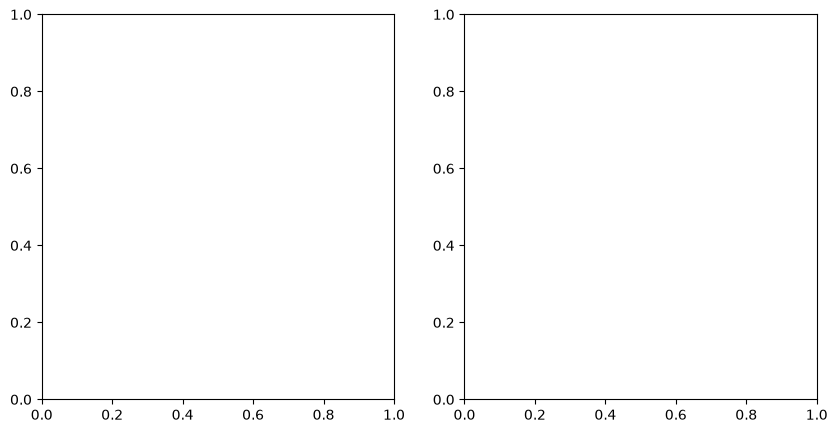

In [ ]:
# Two features weight vector test to show superposition of features in the hidden layer
n = 2 # number of input features
m = 1 # number of hidden units
batch_size = 1000
importance = torch.ones(n).float()  # importance of each feature
S = 0.9 # threshold for generating the dataset
model_1 = NeuralNetwork(n, m, nn.ReLU())
W = train_model(n, batch_size, S, model_1, importance)

import matplotlib.pyplot as plt
fig, axs = plt.subplots(1, 2, figsize=(10, 5))
axs.axhline(0, color='black', lw=0.5, ls='--')
for i in range(2):
    
plt.tight_layout()

In [53]:
# Larger feature weight vector test to show superposition of features in the hidden layer
n = 20 # number of input features
m = 5 # number of hidden units
importance = torch.arange(0, n).float()  # importance of each feature
importance = torch.pow(0.7, importance)  # apply a power transformation to the importance values
S_list = [0, 0.7, 0.9, 0.97, 0.99, 0.997, 0.999] # thresholds for generating the dataset
model_relu = NeuralNetwork(n, m, nn.ReLU())
relu = {}
for S in S_list:
    for i in range(3):  # Run over 3 seeds for each S value
        torch.manual_seed(i)  # Set the seed for reproducibility
        train_model(n, batch_size, S, model_relu, importance)
        if S == 0.7 and i == 1:  # Store the weights only for the second seed of S=0.7 to avoid overwriting
            relu[S] = model_relu.weight.detach().clone().numpy()  # Store the weights for S=0.7
        elif i == 0:  # Store the weights only for the first seed to avoid overwriting
            relu[S] = model_relu.weight.detach().clone().numpy()  # Store the weights for each S value

0 0.046434205025434494
0 0.046451371163129807
0 0.04757887125015259
0.7 0.03392419591546059
0.7 0.034987837076187134
0.7 0.03273729234933853
0.9 0.00724873086437583
0.9 0.009067997336387634
0.9 0.009125841781497002
0.97 0.0011465776478871703
0.97 0.0013404152123257518
0.97 0.001155079691670835
0.99 0.0002246412477688864
0.99 0.0002773601154331118
0.99 0.00027852607308886945
0.997 7.211901538539678e-05
0.997 0.00010650498006725684
0.997 0.00010698474943637848
0.999 1.6288853657897562e-05
0.999 3.987529271398671e-05
0.999 5.7109409681288525e-05


In [54]:
linear = {}
model_linear = NeuralNetwork(n, m, nn.Identity())
for S in S_list:
    for i in range(3):  # Run over 3 seeds for each S value
        torch.manual_seed(i)  # Set the seed for reproducibility
        train_model(n, batch_size, S, model_linear, importance)
        if S == 0.7 and i == 1:  # Store the weights only for the second seed of S=0.7 to avoid overwriting
            linear[S] = model_linear.weight.detach().clone().numpy()  # Store the weights for S=0.7
        elif i == 0:  # Store the weights only for the first seed to avoid overwriting
            linear[S] = model_linear.weight.detach().clone().numpy()  # Store the weights for each S value


0 0.0464324876666069
0 0.046448059380054474
0 0.04758306220173836
0.7 0.04332762584090233
0.7 0.04310280457139015
0.7 0.04394875466823578
0.9 0.016944393515586853
0.9 0.0169525146484375
0.9 0.017416778951883316
0.97 0.00512693403288722
0.97 0.005410339217633009
0.97 0.005613056942820549
0.99 0.0017065090360119939
0.99 0.0015880761202424765
0.99 0.0019985127728432417
0.997 0.0002827899588737637
0.997 0.00032865843968465924
0.997 0.00043914842535741627
0.999 7.087623816914856e-05
0.999 8.577940025134012e-05
0.999 0.00014146736066322774


In [55]:
print(relu)

print(linear)
torch.allclose(torch.tensor(relu[0]), torch.tensor(relu[0.999]))  # Check if the weights for S=0 and S=0.999 are close

{0: array([[-7.2346276e-01, -2.3388270e-01,  2.0817560e-01,  3.1140000e-01,
         5.3071785e-01,  2.9409567e-03,  6.7323365e-04, -4.4508692e-04,
        -9.5360796e-04, -1.6434184e-04, -6.7565637e-04,  6.5656309e-04,
        -2.4814825e-04,  3.2322438e-04, -1.0034975e-04,  2.9296754e-04,
        -8.1297156e-05,  1.0203319e-05, -2.8643088e-04, -7.9711383e-05],
       [ 2.5844115e-01, -4.6668315e-01, -7.2908688e-01,  5.9844707e-03,
         4.2886779e-01,  1.5800969e-04, -1.3429263e-03, -2.4669280e-03,
        -1.4547971e-03,  1.9233971e-04,  3.4556939e-04,  6.1151033e-05,
        -1.2937441e-04,  3.2381539e-04,  2.6186253e-04,  2.9330276e-04,
         2.2370594e-04,  2.6442911e-04,  2.6528808e-04,  2.1367861e-04],
       [-1.7000125e-01, -1.1507761e-02,  1.0117298e-01, -9.4068599e-01,
         2.7536198e-01, -2.7939451e-03, -1.6873368e-03, -9.0885279e-04,
         3.1957843e-03, -2.3986727e-04,  7.3453278e-04,  4.5844718e-04,
        -3.8472112e-04,  2.1798551e-06,  4.1925610e-04,  1

False

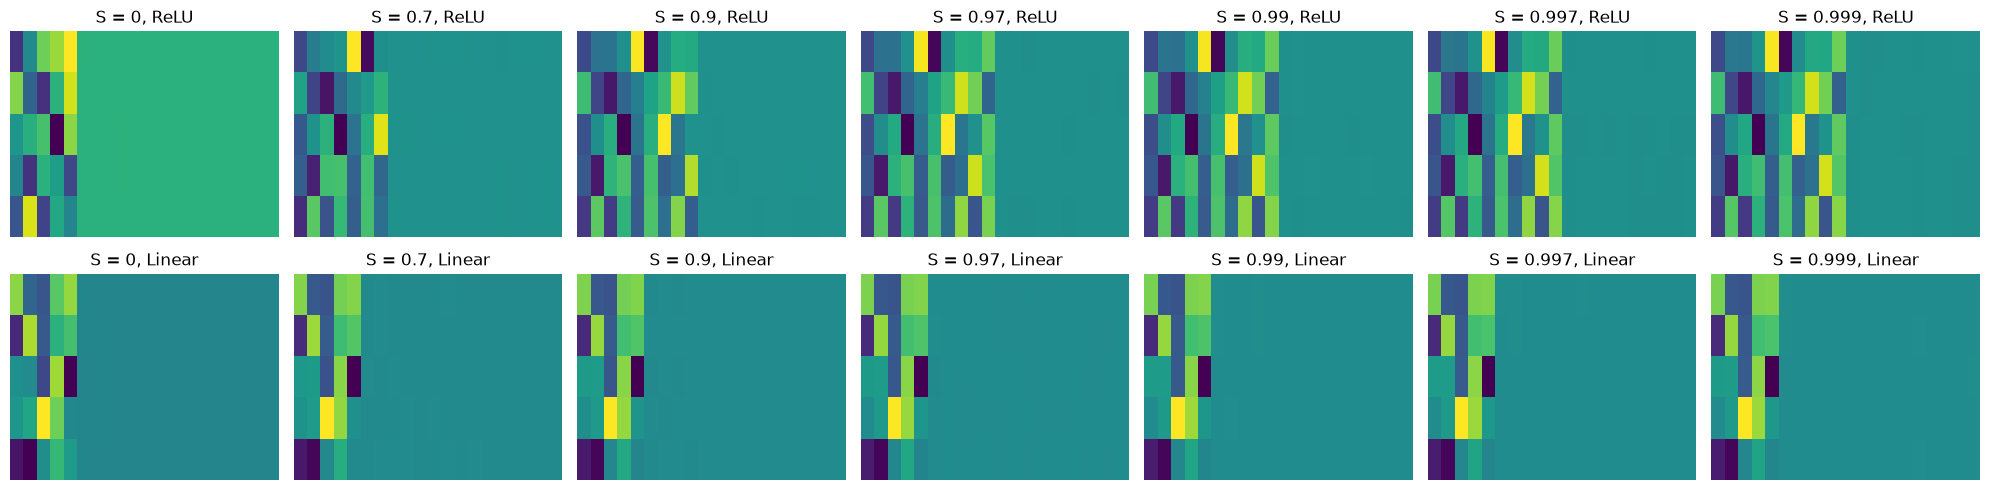

In [68]:
import matplotlib.pyplot as plt
fig, axs = plt.subplots(2,7, figsize=(20, 5))
for i, S in enumerate(relu.keys()):
    axs[0, i].imshow(relu[S], cmap='viridis', aspect='auto')
    axs[0, i].set_title(f'S = {S}, ReLU')
    axs[0, i].axis('off')

    axs[1, i].imshow(linear[S], cmap='viridis', aspect='auto')
    axs[1, i].set_title(f'S = {S}, Linear')
    axs[1, i].axis('off')

plt.tight_layout()
plt.savefig('superposition_weights_map.png')
plt.show()

/tmp/ipykernel_5496/3264427947.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


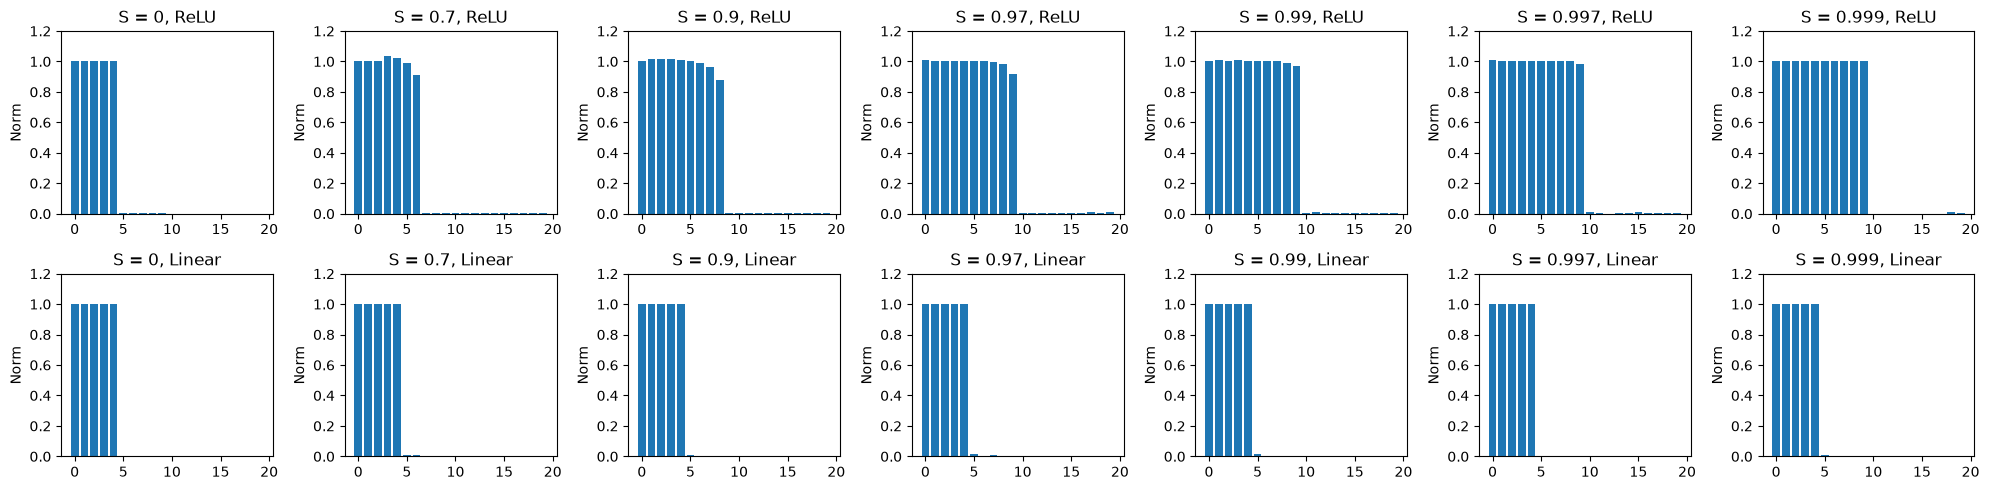

In [70]:
plt, axs = plt.subplots(2,7, figsize=(20, 5))
for i, S in enumerate(relu.keys()):
    R = torch.linalg.norm(torch.tensor(relu[S]), dim = 0)
    axs[0, i].set_ylim(0, 1.2)
    axs[0, i].bar(range(len(R)), R)
    axs[0, i].set_title(f'S = {S}, ReLU')

    axs[0, i].set_ylabel('Norm')

    L = torch.linalg.norm(torch.tensor(linear[S]), dim = 0)
    axs[1, i].set_ylim(0, 1.2)
    axs[1, i].bar(range(len(L)), L)
    axs[1, i].set_title(f'S = {S}, Linear')
    axs[1, i].set_ylabel('Norm')
plt.tight_layout()
plt.savefig('superposition_weights_bar.png', dpi=300)
plt.show()